# FER-2013 Facial Expression Recognition

## Dataset Preparation and Exploratory Data Analysis (EDA)

**Dataset:** FER-2013

**Dataset Source:** [FER-2013 on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

**Framework:** TensorFlow/Keras

### Objective

The objective of this notebook is to prepare and explore the FER-2013 dataset before developing a Convolutional Neural Network (CNN) for facial expression recognition.

The notebook covers:

- Dataset inspection and image integrity checks.
- Exploratory Data Analysis (EDA).
- Training and validation data splitting.
- Image preprocessing and label encoding.
- Preparation of the final dataset for CNN model development.

### 1. Environment Setup and Dataset Loading


In [2]:
# Import required libraries

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


### 1.1 Extracting the Dataset


The dataset is organized into two main folders:

- `train`: Contains images used for model training and validation.
- `test`: Contains images reserved for final model evaluation.

In [3]:
# Define dataset location

dataset_path = "../data"

# Define the seven emotion categories

classes = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "sad",
    "surprise",
    "neutral"
]

print("Dataset path:", dataset_path)

print("Emotion categories:", classes)

Dataset path: ../data
Emotion categories: ['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']


### 1.2 Verifying the Dataset Structure

In [4]:
# Check dataset folder structure

for split in ["train", "test"]:

    print("\n", split.upper())

    for emotion in classes:

        folder = os.path.join(
            dataset_path,
            split,
            emotion
        )

        if os.path.exists(folder):
            print(emotion, "- Folder exists")
        else:
            print(emotion, "- Folder missing")


 TRAIN
angry - Folder exists
disgust - Folder exists
fear - Folder exists
happy - Folder exists
sad - Folder exists
surprise - Folder exists
neutral - Folder exists

 TEST
angry - Folder exists
disgust - Folder exists
fear - Folder exists
happy - Folder exists
sad - Folder exists
surprise - Folder exists
neutral - Folder exists


### 1.3 Counting Images in Each Emotion Category

In [5]:
# Count images in each emotion category

image_counts = []

for split in ["train", "test"]:

    for emotion in classes:

        folder = os.path.join(
            dataset_path,
            split,
            emotion
        )

        # Count only image files
        count = len([
            file for file in os.listdir(folder)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        image_counts.append({
            "Dataset": split,
            "Emotion": emotion,
            "Number of Images": count
        })

# Convert results into a DataFrame
df_counts = pd.DataFrame(image_counts)

print(df_counts)

   Dataset   Emotion  Number of Images
0    train     angry              3995
1    train   disgust               436
2    train      fear              4097
3    train     happy              7215
4    train       sad              4830
5    train  surprise              3171
6    train   neutral              4965
7     test     angry               958
8     test   disgust               111
9     test      fear              1024
10    test     happy              1774
11    test       sad              1247
12    test  surprise               831
13    test   neutral              1233


In [6]:
# Calculate total images in each dataset

print("Training images:",
      df_counts[df_counts["Dataset"] == "train"]["Number of Images"].sum())

print("Testing images:",
      df_counts[df_counts["Dataset"] == "test"]["Number of Images"].sum())

print("Total images:",
      df_counts["Number of Images"].sum())

Training images: 28709
Testing images: 7178
Total images: 35887


Image name: Training_10019449.jpg
Image dimensions: (48, 48)
Image mode: L


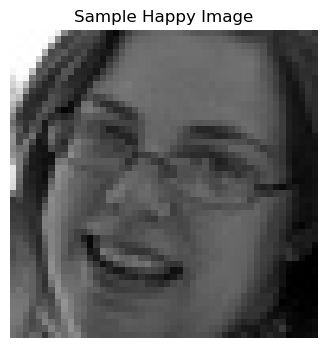

In [7]:
# Select one image from the training dataset

sample_folder = os.path.join(
    dataset_path,
    "train",
    "happy"
)

sample_image_name = os.listdir(sample_folder)[0]

sample_image_path = os.path.join(
    sample_folder,
    sample_image_name
)

# Open the image
img = Image.open(sample_image_path)

# Display image information
print("Image name:", sample_image_name)
print("Image dimensions:", img.size)
print("Image mode:", img.mode)

# Display the image
plt.figure(figsize=(4, 4))
plt.imshow(img, cmap="gray")
plt.title("Sample Happy Image")
plt.axis("off")
plt.show()

### 1.4 Checking Image Dimensions and Integrity

In [8]:

dimension_errors = []
mode_counts = {}

for split in ["train", "test"]:

    for emotion in classes:

        folder = os.path.join(dataset_path, split, emotion)

        for filename in os.listdir(folder):

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:

                    if img.size != (48, 48):
                        dimension_errors.append(path)

                    mode_counts[img.mode] = (
                        mode_counts.get(img.mode, 0) + 1
                    )

            except Exception:
                pass

print("Images with incorrect dimensions:", len(dimension_errors))
print("Image modes:", mode_counts)

Images with incorrect dimensions: 0
Image modes: {'L': 35887}


In [9]:
# Check for corrupted or unreadable images

corrupted_images = []

for split in ["train", "test"]:

    for emotion in classes:

        folder = os.path.join(dataset_path, split, emotion)

        for filename in os.listdir(folder):

            path = os.path.join(folder, filename)

            try:
                with Image.open(path) as img:
                    img.verify()

            except Exception:
                corrupted_images.append(path)

print("Total corrupted images:", len(corrupted_images))

Total corrupted images: 0


### 2. Exploratory Data Analysis (EDA)

### 2.1 Class Distribution

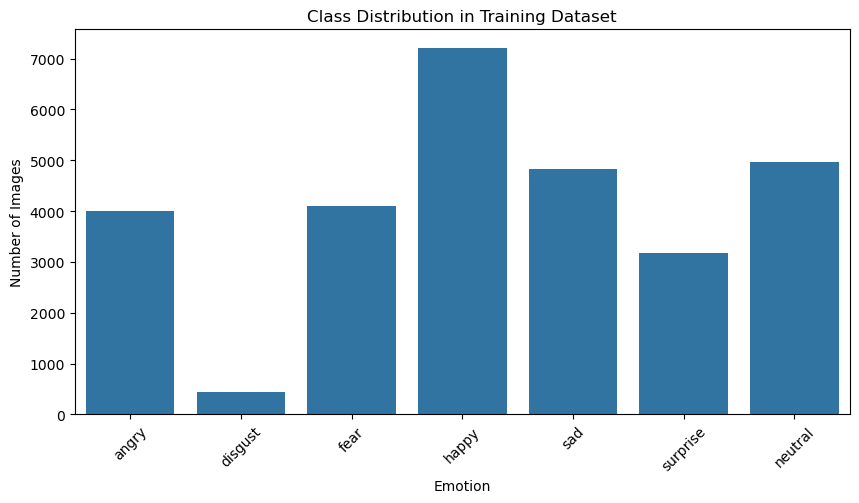

In [10]:
# Visualize the number of images in each emotion class

train_counts = df_counts[df_counts["Dataset"] == "train"]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=train_counts,
    x="Emotion",
    y="Number of Images"
)

plt.title("Class Distribution in Training Dataset")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

### 2.2 Sample Images from Each Emotion Category

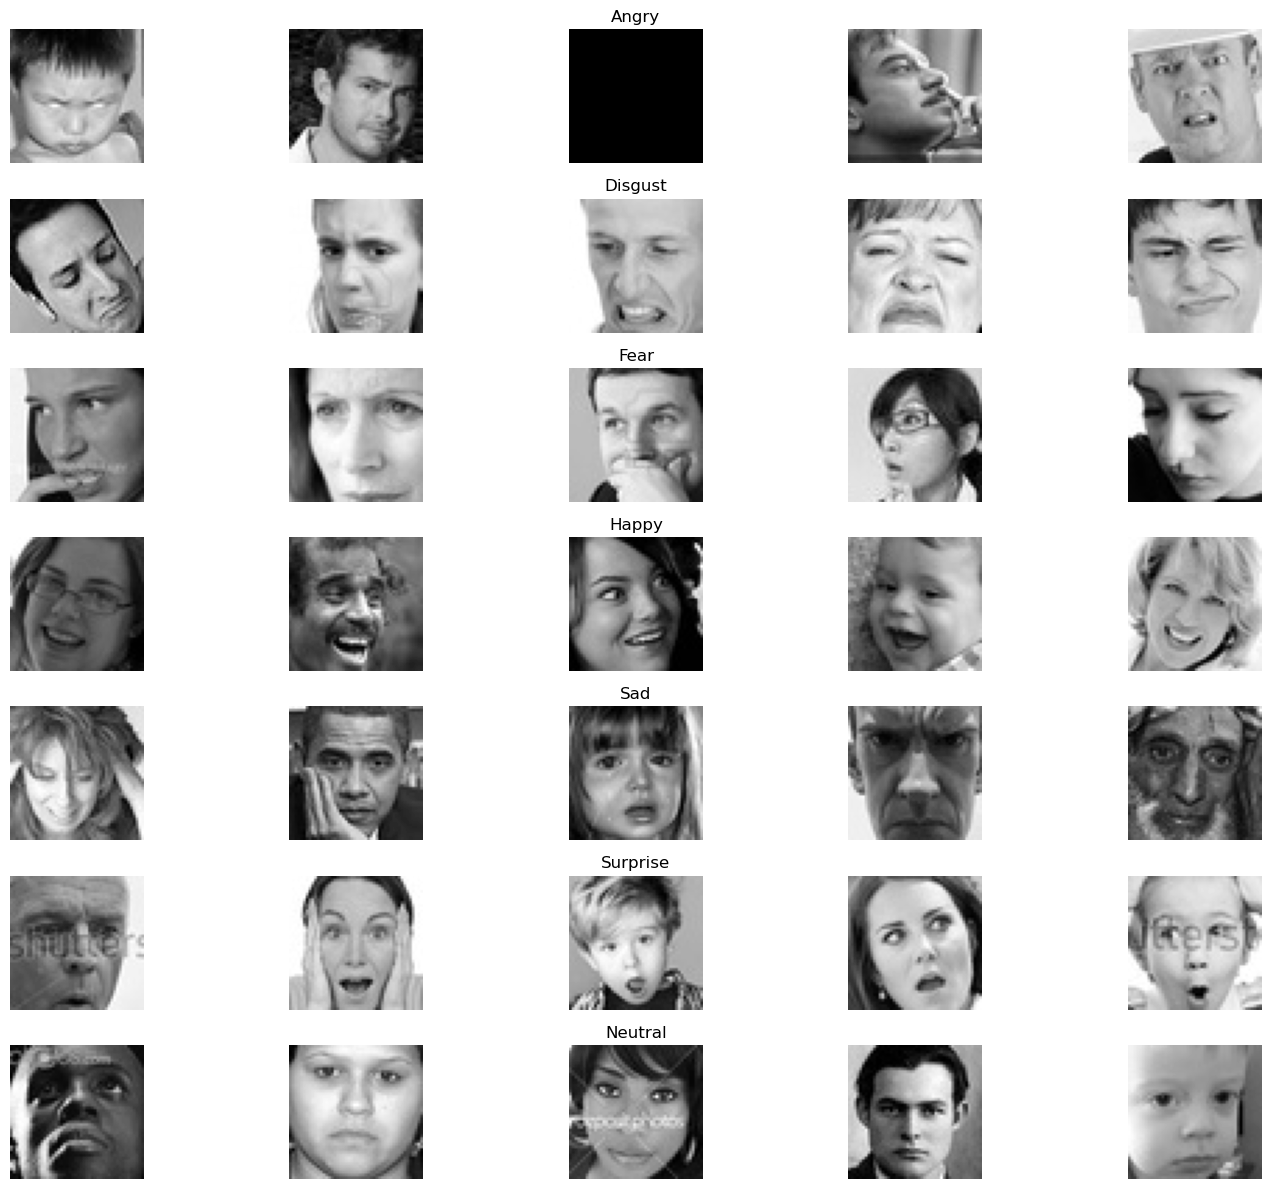

In [11]:


plt.figure(figsize=(15, 12))

for row, emotion in enumerate(classes):
    folder = os.path.join(dataset_path, "train", emotion)

    image_files = os.listdir(folder)[:5]

    for col, image_file in enumerate(image_files):
        image_path = os.path.join(folder, image_file)

        img = Image.open(image_path)

        plt.subplot(7, 5, row * 5 + col + 1)
        plt.imshow(img, cmap="gray")
        plt.axis("off")

        if col == 2:
            plt.title(emotion.capitalize())

plt.tight_layout()
plt.show()

**Observations:**

- The dataset contains seven emotion categories: angry, disgust, fear, happy, sad, surprise, and neutral.
- The `happy` category has the highest number of images.
- The `disgust` category has the lowest number of images.
- The number of images is not equally distributed across all emotion categories. This indicates class imbalance in the dataset.

**Inference:**

Since the dataset is imbalanced, the model may learn some emotion categories better than others. Therefore, we should consider evaluation metrics such as precision, recall, and macro F1-score in addition to accuracy.

### 2.3 Average Face for Each Emotion

In [12]:
# Calculate the average face for each emotion using training images

average_faces = {}

for emotion in classes:
    folder = os.path.join(dataset_path, "train", emotion)

    images = []

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        img = Image.open(image_path).convert("L")
        img_array = np.array(img, dtype=np.float32)

        images.append(img_array)

    # Calculate pixel-wise average
    average_face = np.mean(images, axis=0)

    average_faces[emotion] = average_face

print("Average faces calculated successfully!")

Average faces calculated successfully!


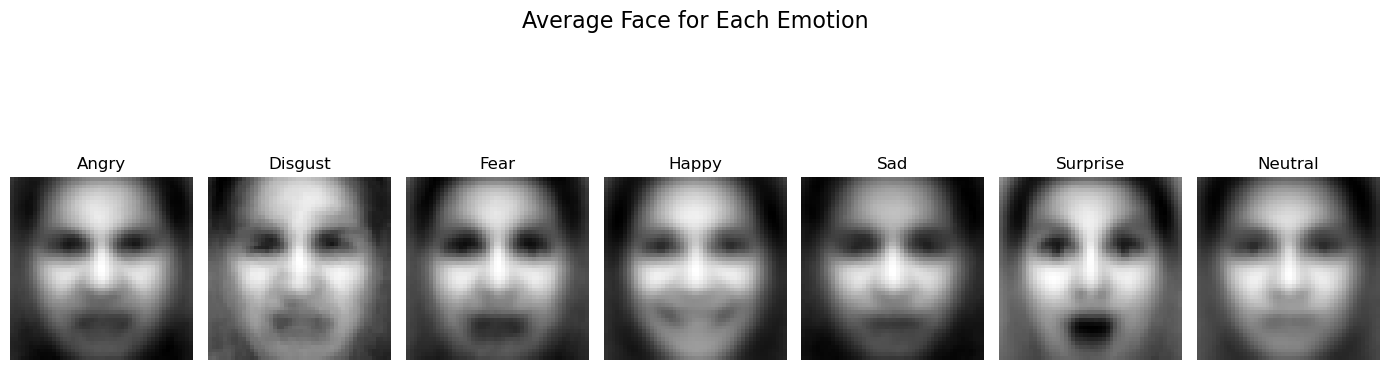

In [13]:
# Display the average face for each emotion

plt.figure(figsize=(14, 5))

for i, emotion in enumerate(classes):
    plt.subplot(1, 7, i + 1)

    plt.imshow(average_faces[emotion], cmap="gray")
    plt.title(emotion.capitalize())
    plt.axis("off")

plt.suptitle("Average Face for Each Emotion", fontsize=16)
plt.tight_layout()
plt.show()

**Observations:**

- Seven average face images are generated, one for each emotion category.
- The average faces appear blurred because the pixel values of many different faces are combined.
- Individual facial details become less visible during averaging.
- The resulting images show general visual patterns, rather than a clear representation of a particular person's face.

**Inference:**

Average face visualization provides a general understanding of each emotion category. However, it does not clearly distinguish all emotions because different facial expressions can share similar visual patterns.

In [14]:
# Collect training image paths and corresponding emotion labels

image_paths = []
image_labels = []

for emotion in classes:
    folder = os.path.join(dataset_path, "train", emotion)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        image_paths.append(image_path)
        image_labels.append(emotion)

print("Total image paths:", len(image_paths))
print("Total labels:", len(image_labels))

Total image paths: 28709
Total labels: 28709


### 3. Training and Validation Data Preparation

Perform stratified splitting

In [15]:
# Split the training data into training and validation sets

X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    image_labels,
    test_size=0.20,
    random_state=42,
    stratify=image_labels
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))

Training samples: 22967
Validation samples: 5742


Verify the emotion distribution in both splits

In [16]:
# Compare emotion distribution in training and validation sets

train_distribution = pd.Series(y_train).value_counts().sort_index()
val_distribution = pd.Series(y_val).value_counts().sort_index()

distribution_df = pd.DataFrame({
    "Emotion": classes,
    "Training Images": [train_distribution.get(c, 0) for c in classes],
    "Validation Images": [val_distribution.get(c, 0) for c in classes]
})

print(distribution_df)

    Emotion  Training Images  Validation Images
0     angry             3196                799
1   disgust              349                 87
2      fear             3277                820
3     happy             5772               1443
4       sad             3864                966
5  surprise             2537                634
6   neutral             3972                993


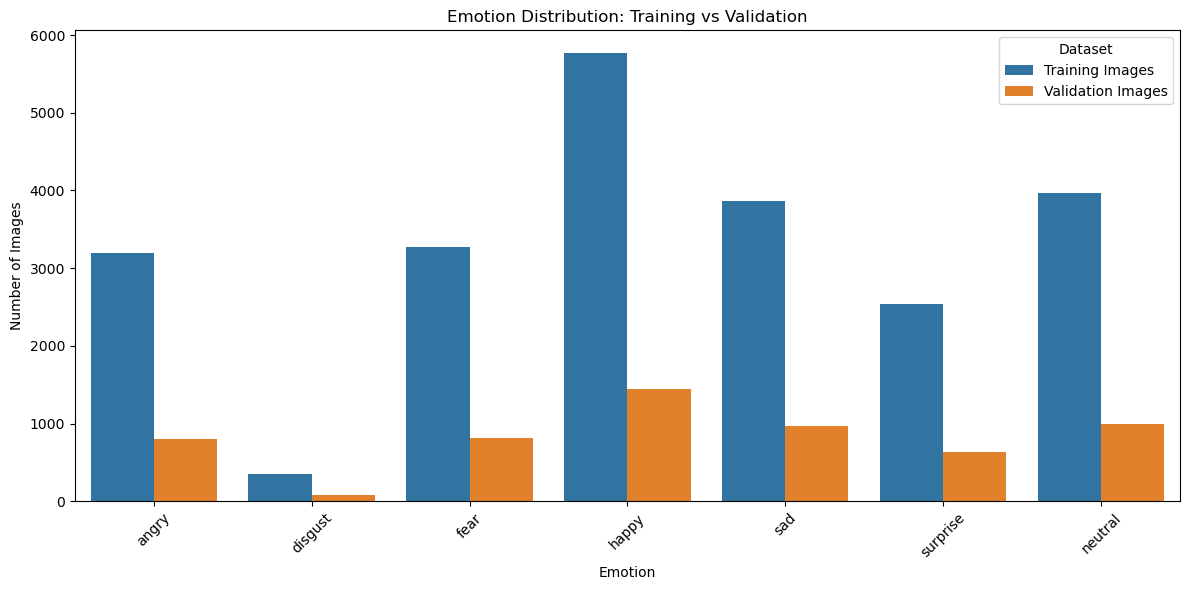

In [17]:
# Visualize training and validation class distributions

distribution_melted = distribution_df.melt(
    id_vars="Emotion",
    value_vars=["Training Images", "Validation Images"],
    var_name="Dataset",
    value_name="Number of Images"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=distribution_melted,
    x="Emotion",
    y="Number of Images",
    hue="Dataset"
)

plt.title("Emotion Distribution: Training vs Validation")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Image preprocessing

In [18]:
# Function to load an image and convert it into a NumPy array

def load_image(image_path):
    img = Image.open(image_path).convert("L")
    img_array = np.array(img, dtype=np.float32)
    return img_array

print("Image loading function created successfully!")

Image loading function created successfully!


In [19]:
# Load all training images into a NumPy array

X_train_images = np.array([
    load_image(path) for path in X_train
])

print("Training image array shape:", X_train_images.shape)

Training image array shape: (22967, 48, 48)


In [20]:
# Load all validation images into a NumPy array

X_val_images = np.array([
    load_image(path) for path in X_val
])

print("Validation image array shape:", X_val_images.shape)

Validation image array shape: (5742, 48, 48)


Normalize the pixel values

In [21]:
# Normalize pixel values to the range 0 to 1

X_train_images = X_train_images / 255.0
X_val_images = X_val_images / 255.0

print("Training pixel range:",
      X_train_images.min(), "to", X_train_images.max())

print("Validation pixel range:",
      X_val_images.min(), "to", X_val_images.max())

Training pixel range: 0.0 to 1.0
Validation pixel range: 0.0 to 1.0


In [22]:
# Add a channel dimension for grayscale images

X_train_images = np.expand_dims(X_train_images, axis=-1)
X_val_images = np.expand_dims(X_val_images, axis=-1)

print("Training shape:", X_train_images.shape)
print("Validation shape:", X_val_images.shape)

Training shape: (22967, 48, 48, 1)
Validation shape: (5742, 48, 48, 1)


In [24]:
# Create a mapping between emotions and numerical labels

label_map = {
    emotion: index
    for index, emotion in enumerate(classes)
}

print("Label mapping:")
print(label_map)

Label mapping:
{'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'sad': 4, 'surprise': 5, 'neutral': 6}


Convert emotion labels into numbers

In [25]:
# Convert training and validation labels into numerical values

y_train_encoded = np.array([
    label_map[label] for label in y_train
])

y_val_encoded = np.array([
    label_map[label] for label in y_val
])

print("Training labels shape:", y_train_encoded.shape)
print("Validation labels shape:", y_val_encoded.shape)

print("\nFirst 10 training labels:")
print(y_train_encoded[:10])

Training labels shape: (22967,)
Validation labels shape: (5742,)

First 10 training labels:
[2 2 0 3 6 3 6 2 0 2]


In [26]:
# Verify that image counts and label counts match

print("Training images:", X_train_images.shape[0])
print("Training labels:", len(y_train_encoded))

print("Validation images:", X_val_images.shape[0])
print("Validation labels:", len(y_val_encoded))

assert X_train_images.shape[0] == len(y_train_encoded)
assert X_val_images.shape[0] == len(y_val_encoded)

print("\nAll image and label counts match!")

Training images: 22967
Training labels: 22967
Validation images: 5742
Validation labels: 5742

All image and label counts match!


Load and process the test images

In [27]:
# Collect test image paths and their corresponding labels

test_image_paths = []
test_labels = []

for emotion in classes:
    folder = os.path.join(dataset_path, "test", emotion)

    for filename in os.listdir(folder):
        image_path = os.path.join(folder, filename)

        test_image_paths.append(image_path)
        test_labels.append(emotion)

print("Total test image paths:", len(test_image_paths))
print("Total test labels:", len(test_labels))

Total test image paths: 7178
Total test labels: 7178


In [28]:
# Load all test images into a NumPy array

X_test_images = np.array([
    load_image(path) for path in test_image_paths
])

print("Test image array shape:", X_test_images.shape)

Test image array shape: (7178, 48, 48)


In [29]:
# Normalize test pixel values to the range 0 to 1

X_test_images = X_test_images / 255.0

print("Test pixel range:",
      X_test_images.min(), "to", X_test_images.max())

Test pixel range: 0.0 to 1.0


In [30]:
# Add a channel dimension to test images

X_test_images = np.expand_dims(X_test_images, axis=-1)

print("Test image shape:", X_test_images.shape)

Test image shape: (7178, 48, 48, 1)


In [31]:
# Convert test emotion labels into numerical values

y_test_encoded = np.array([
    label_map[label] for label in test_labels
])

print("Test labels shape:", y_test_encoded.shape)

print("\nFirst 10 test labels:")
print(y_test_encoded[:10])

Test labels shape: (7178,)

First 10 test labels:
[0 0 0 0 0 0 0 0 0 0]


In [32]:
# Final verification of the prepared datasets

print("========== FINAL DATASET SUMMARY ==========")

print("\nTRAINING DATA")
print("Images:", X_train_images.shape)
print("Labels:", y_train_encoded.shape)

print("\nVALIDATION DATA")
print("Images:", X_val_images.shape)
print("Labels:", y_val_encoded.shape)

print("\nTESTING DATA")
print("Images:", X_test_images.shape)
print("Labels:", y_test_encoded.shape)

# Verify image-label counts
assert len(X_train_images) == len(y_train_encoded)
assert len(X_val_images) == len(y_val_encoded)
assert len(X_test_images) == len(y_test_encoded)

# Verify image dimensions
assert X_train_images.shape[1:] == (48, 48, 1)
assert X_val_images.shape[1:] == (48, 48, 1)
assert X_test_images.shape[1:] == (48, 48, 1)

# Verify normalized pixel ranges
assert X_train_images.min() >= 0 and X_train_images.max() <= 1
assert X_val_images.min() >= 0 and X_val_images.max() <= 1
assert X_test_images.min() >= 0 and X_test_images.max() <= 1

print("\nAll verification checks passed!")

========== FINAL DATASET SUMMARY ==========

TRAINING DATA
Images: (22967, 48, 48, 1)
Labels: (22967,)

VALIDATION DATA
Images: (5742, 48, 48, 1)
Labels: (5742,)

TESTING DATA
Images: (7178, 48, 48, 1)
Labels: (7178,)

All verification checks passed!


In [36]:
# Save all prepared datasets into one compressed file

np.savez_compressed(
    "../processed/fer2013_preprocessed.npz",
    X_train=X_train_images,
    y_train=y_train_encoded,
    X_val=X_val_images,
    y_val=y_val_encoded,
    X_test=X_test_images,
    y_test=y_test_encoded
)

print("Preprocessed dataset saved successfully as fer2013_preprocessed.npz!")

Preprocessed dataset saved successfully as fer2013_preprocessed.npz!


In [37]:
import numpy as np

data = np.load("../processed/fer2013_preprocessed.npz")

print("Available arrays:", data.files)

for name in data.files:
    print(name, data[name].shape)

Available arrays: ['X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test']
X_train (22967, 48, 48, 1)
y_train (22967,)
X_val (5742, 48, 48, 1)
y_val (5742,)
X_test (7178, 48, 48, 1)
y_test (7178,)


### 4. Final Preprocessed Dataset Summary

This section summarises the final training, validation, and testing datasets prepared for CNN model development.

### 4.1 Dataset Details

The FER-2013 dataset was divided into three parts:

- **Training Set:** 22,967 images (80% of the original training data). Used to train the CNN model.
- **Validation Set:** 5,742 images (20% of the original training data). Used to evaluate the model during training and monitor its performance.
- **Testing Set:** 7,178 images. Kept separate from the training and validation sets and used for final model evaluation.

### 4.2 Image Preprocessing

All images were preprocessed before being used for CNN model development:

- **Image Size:** 48 × 48 pixels.
- **Image Format:** Grayscale.
- **Normalization:** Pixel values were scaled from the range 0–255 to 0–1.
- **Channel Dimension:** A single channel was added to represent grayscale images.
- **Label Encoding:** The seven emotion categories were converted into numerical labels from 0 to 6.

### 4.3 Final Dataset Shapes

| Dataset | Image Shape | Label Shape |
|---|---|---|
| Training | (22967, 48, 48, 1) | (22967,) |
| Validation | (5742, 48, 48, 1) | (5742,) |
| Testing | (7178, 48, 48, 1) | (7178,) |

**Conclusion:**

The FER-2013 dataset has been successfully inspected, explored, split, and preprocessed. The final datasets are ready to be used for developing and training the CNN-based facial expression recognition model.